# Étape 1 — Analyse des données (EDA)

> *« Foncer, c'est échouer. Ce n'est pas parce que l'IA va faire tout le travail que vous ne devez pas connaître vos données ! »* — cours de J. Breton

**Objectif :** comprendre nos données **avant** d'entraîner le moindre modèle. Chaque constat de ce notebook doit se traduire par une décision pour la suite du projet (taille d'entrée du détecteur, gestion du déséquilibre, augmentation, découpage train/validation/test…).

On suit la méthode du cours, en 4 étapes, puis on regarde les images :

1. **Inspection initiale** : contexte, volumétrie, dictionnaire de données, types, cible
2. **Qualité des données** : valeurs manquantes, doublons, cohérence, crédibilité
3. **Analyse univariée** : chaque variable séparément
4. **Analyse bivariée / multivariée** : les relations entre variables, et surtout avec la **cible**
5. **Voir les données** : images annotées et galerie d'avions par classe
6. **Conclusions** : ce qu'on retient et ce que ça change pour la suite

**Mode d'emploi :** exécute les cellules **une par une** (`Maj + Entrée`), lis l'explication au-dessus de chaque cellule et regarde le résultat. Dans les encadrés **« Tes observations »**, note ce que tu remarques : ces notes serviront pour le rapport et l'oral. Pour enregistrer aussi les figures importantes dans `reports/figures/eda/` (rapport, slides), mets `ENREGISTRER = True` dans la première cellule de code.

## 0. Préparation

On importe les bibliothèques :

| Bibliothèque | Rôle |
|---|---|
| `pandas` | tableaux de données (comme un Excel programmable) |
| `numpy` | calcul sur des tableaux de nombres |
| `matplotlib`, `seaborn` | graphiques |
| `cv2` (OpenCV) | lecture et traitement d'images |
| `xml.etree.ElementTree` | lecture des fichiers XML d'annotations |

In [1]:
import hashlib
import xml.etree.ElementTree as ET
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

# Le notebook se lance depuis le dossier etapes/ : la racine du projet est le dossier parent
RACINE = Path.cwd().parent
RAW_IMAGES_DIR = RACINE / "data" / "raw" / "images"  # 1331 images satellites .jpg
RAW_ANNOTATIONS_DIR = RACINE / "data" / "raw" / "annotations"  # 1331 fichiers .xml (Pascal VOC)
assert RAW_IMAGES_DIR.exists(), f"Dataset du prof introuvable : {RAW_IMAGES_DIR}"

# Les 20 types d'avions, dans l'ordre NUMÉRIQUE (un tri alphabétique donnerait A1, A10, A11...
# et les numéros de classe seraient décalés sans erreur visible)
CLASSES = [f"A{i}" for i in range(1, 21)]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASSES)}

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)

# Générateur de nombres aléatoires avec une graine fixe : les tirages « au hasard »
# (images d'exemple, galerie) seront les mêmes à chaque exécution -> résultats reproductibles.
rng = np.random.default_rng(42)

# True : enregistre aussi les figures importantes dans reports/figures/eda/ (rapport, slides)
ENREGISTRER = False
FIG_DIR = RACINE / "reports" / "figures" / "eda"


def save(fig, name):
    if ENREGISTRER:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Images      :", RAW_IMAGES_DIR)
print("Annotations :", RAW_ANNOTATIONS_DIR)

Images      : C:\Users\deror\Desktop\projet_ia\data\raw\images
Annotations : C:\Users\deror\Desktop\projet_ia\data\raw\annotations


Nos trois outils de lecture et d'affichage, utilisés dans tout le notebook :

| Fonction | Rôle |
|---|---|
| `load_annotations()` | lit les 1 331 fichiers XML et en fait un tableau, **une ligne par avion** |
| `load_image_rgb()` | charge une image dans le bon ordre des couleurs (RGB) |
| `draw_boxes()` | dessine les boîtes des avions, une couleur par type |

In [2]:
def read_voc_file(xml_path: Path) -> list[dict]:
    """Lit un fichier XML et renvoie une liste de dictionnaires, un par avion annoté."""
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    image_width = int(size.findtext("width"))
    image_height = int(size.findtext("height"))

    rows = []
    for obj in root.iter("object"):
        box = obj.find("bndbox")
        rows.append(
            {
                "image_id": Path(xml_path).stem,  # "1005" pour "1005.xml"
                "image_width": image_width,
                "image_height": image_height,
                "class_name": obj.findtext("name"),
                "xmin": int(box.findtext("xmin")),
                "ymin": int(box.findtext("ymin")),
                "xmax": int(box.findtext("xmax")),
                "ymax": int(box.findtext("ymax")),
                # "1" si l'avion est coupé par le bord de l'image
                "truncated": obj.findtext("truncated") == "1",
                # "1" si l'annotateur a jugé l'avion difficile à reconnaître
                "difficult": obj.findtext("difficult") == "1",
            }
        )
    return rows


def load_annotations(annotations_dir: Path = RAW_ANNOTATIONS_DIR) -> pd.DataFrame:
    """Charge tous les fichiers XML d'un dossier dans un tableau : une ligne par avion.

    On ajoute aussi des colonnes calculées à partir des coordonnées de la boîte :
    largeur, hauteur, aire, rapport largeur/hauteur et position du centre.
    """
    rows = []
    for xml_path in sorted(Path(annotations_dir).glob("*.xml")):
        rows.extend(read_voc_file(xml_path))
    df = pd.DataFrame(rows)

    df["box_width"] = df["xmax"] - df["xmin"]
    df["box_height"] = df["ymax"] - df["ymin"]
    df["box_area"] = df["box_width"] * df["box_height"]
    df["aspect_ratio"] = df["box_width"] / df["box_height"]  # > 1 : boîte plus large que haute
    # Centre de la boîte, en proportion de l'image (0 = bord gauche/haut, 1 = bord droit/bas)
    df["center_x"] = (df["xmin"] + df["xmax"]) / 2 / df["image_width"]
    df["center_y"] = (df["ymin"] + df["ymax"]) / 2 / df["image_height"]
    return df


def load_image_rgb(image_path: Path) -> np.ndarray:
    """Charge une image en couleurs, au format RGB (tableau hauteur x largeur x 3).

    OpenCV lit les images en BGR (bleu, vert, rouge) pour des raisons historiques,
    alors que matplotlib et PyTorch attendent du RGB : on inverse donc les canaux.
    """
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"Impossible de lire l'image : {image_path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def class_color(class_name: str) -> tuple[int, int, int]:
    """Couleur RGB (0-255) fixe pour chaque classe, tirée de la palette « tab20 » (20 couleurs)."""
    r, g, b, _ = plt.get_cmap("tab20")(CLASS_TO_INDEX[class_name])
    return int(r * 255), int(g * 255), int(b * 255)


def draw_boxes(image, boxes, labels, thickness=2):
    """Dessine des boîtes (xmin, ymin, xmax, ymax) et leur étiquette sur une COPIE de l'image RGB.

    Chaque étiquette doit commencer par un nom de classe (ex. "A10 0.93") : il sert à choisir
    la couleur de la boîte.
    """
    image = image.copy()  # on ne modifie pas l'image d'origine
    colors = [class_color(label.split()[0]) for label in labels]
    for (xmin, ymin, xmax, ymax), label, color in zip(boxes, labels, colors, strict=True):
        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), color, thickness)
        cv2.putText(
            image, label, (xmin, max(ymin - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2
        )
    return image

In [3]:
# Une couleur fixe par classe, la même dans tous les graphiques (valeurs de 0 à 1)
PALETTE = {c: tuple(v / 255 for v in class_color(c)) for c in CLASSES}

## 1. Inspection initiale

Le premier coup d'œil : d'où viennent les données, combien il y en a, que contient chaque colonne, et que cherche-t-on à prédire.

### 1.1 Le contexte

- **Origine :** des images satellites (Google Earth) de bases aériennes militaires, issues du dataset public **MAR20** (*Military Aircraft Recognition*, 2023).
- **Contenu :** 20 types d'avions militaires, codés **A1 à A20** (les vrais noms ne sont pas donnés).
- **Collecte :** les avions ont été encadrés et étiquetés **à la main** par des annotateurs humains. Ils ont donc pu faire des erreurs, et c'est ce qu'on vérifie dans la partie 2.
- **Notre part :** le prof nous donne la partie « entraînement » officielle de MAR20. C'est à nous d'en mettre une partie de côté (le jeu de **test**) pour vérifier, à la fin, que notre application marche sur des images jamais vues.
- **Objectif métier :** surveiller automatiquement des bases aériennes (renseignement), comme la surveillance maritime par satellite d'Unseenlabs vue en cours.

### 1.2 À quoi ressemble une annotation ?

Chaque image `XXXX.jpg` a un fichier texte `XXXX.xml` au format **Pascal VOC**. Ouvrons-en un :

In [4]:
premier_xml = min(RAW_ANNOTATIONS_DIR.glob("*.xml"))  # le premier fichier par ordre alphabétique
print(premier_xml.name)
print(premier_xml.read_text())

1005.xml
<annotation>
	<folder>Unknown</folder>
	<filename>1005.jpg</filename>
	<path>Unknown</path>
	<size>
		<width>800</width>
		<height>800</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>A2</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>275</xmin>
			<ymin>22</ymin>
			<xmax>385</xmax>
			<ymax>149</ymax>
		</bndbox>
	</object>
	<object>
		<name>A10</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>262</xmin>
			<ymin>470</ymin>
			<xmax>404</xmax>
			<ymax>596</ymax>
		</bndbox>
	</object>
</annotation>


Les balises importantes :

| Balise | Signification |
|---|---|
| `<size>` | largeur, hauteur et nombre de canaux de couleur (3 = rouge, vert, bleu) de l'image |
| `<object>` | **un avion** (il y a autant de balises `<object>` que d'avions dans l'image) |
| `<name>` | sa **classe** (A1…A20) |
| `<bndbox>` | sa **boîte englobante** : le plus petit rectangle horizontal qui contient l'avion |
| `<truncated>` | 1 si l'avion est coupé par le bord de l'image |
| `<difficult>` | 1 si l'annotateur l'a jugé difficile à reconnaître |

Les coordonnées sont en **pixels**, avec l'origine **en haut à gauche** (l'axe y descend) :

```
(0,0) ──────────────────► x
  │      (xmin, ymin)
  │           ┌──────────┐
  │           │  avion   │
  │           └──────────┘
  │                 (xmax, ymax)
  ▼ y
```

### 1.3 Charger toutes les annotations dans un tableau

Lire 1331 fichiers XML à la main serait pénible. La fonction `load_annotations()` (définie au début du notebook) les parcourt tous et construit un **DataFrame pandas** avec **une ligne par avion**. Elle ajoute aussi des colonnes calculées : largeur, hauteur, aire de la boîte, etc.

In [5]:
df = load_annotations()
df.head(10)

,image_id,image_width,image_height,class_name,xmin,ymin,xmax,ymax,truncated,difficult,box_width,box_height,box_area,aspect_ratio,center_x,center_y
0,1005,800,800,A2,275,22,385,149,False,False,110,127,13970,0.87,0.41,0.11
1,1005,800,800,A10,262,470,404,596,False,False,142,126,17892,1.13,0.42,0.67
2,1008,800,800,A2,108,2,214,113,False,False,106,111,11766,0.95,0.20,0.07
3,1008,800,800,A2,192,47,296,178,False,False,104,131,13624,0.79,0.30,0.14
4,1008,800,800,A2,108,122,215,250,False,False,107,128,13696,0.84,0.20,0.23
5,1008,800,800,A2,194,189,297,327,False,False,103,138,14214,0.75,0.31,0.32
6,1008,800,800,A2,115,255,219,396,False,False,104,141,14664,0.74,0.21,0.41
7,1008,800,800,A2,196,325,300,466,False,False,104,141,14664,0.74,0.31,0.49
8,1008,800,800,A2,107,403,216,536,False,False,109,133,14497,0.82,0.20,0.59
9,1008,800,800,A2,194,469,304,605,False,False,110,136,14960,0.81,0.31,0.67


On construit aussi un deuxième tableau avec **une ligne par image**. `groupby("image_id")` regroupe les lignes de chaque image, puis `agg` calcule un résumé par groupe.

In [6]:
images = df.groupby("image_id").agg(
    image_width=("image_width", "first"),
    image_height=("image_height", "first"),
    n_avions=("class_name", "size"),  # nombre de lignes = nombre d'avions
    n_classes=("class_name", "nunique"),  # nombre de types d'avions différents
)

print(f"Nombre d'images annotées : {len(images)}")
print(f"Nombre d'avions annotés  : {len(df)}")
print(f"Nombre de classes        : {df['class_name'].nunique()}")
print(f"Tableau des avions       : {df.shape[0]} lignes x {df.shape[1]} colonnes")
images.head()

Nombre d'images annotées : 1331
Nombre d'avions annotés  : 7870
Nombre de classes        : 20
Tableau des avions       : 7870 lignes x 16 colonnes


,image_width,image_height,n_avions,n_classes
image_id,,,,
1005,800,800,2,2
1008,800,800,11,1
1010,800,800,5,2
1017,800,800,3,1
1021,800,800,3,1


**Volumétrie :** quelques milliers de lignes et environ 425 Mo d'images. Ce n'est **pas du Big Data** : tout tient en mémoire sur un PC portable, et on n'a pas besoin d'outils spécialisés.

### 1.4 Le dictionnaire de données

Le cours insiste : *« S'il n'existe pas, il faut le créer. »* Le voici pour notre tableau `df` (une ligne = un avion) :

| Colonne | Signification | Type |
|---|---|---|
| `image_id` | nom du fichier image, sans extension | catégoriel nominal (un **identifiant**, pas un nombre à additionner !) |
| `image_width`, `image_height` | taille de l'image, en pixels | numérique discret |
| `class_name` | type d'avion, A1 à A20 | catégoriel nominal (**cible de la classification**) |
| `xmin`, `ymin`, `xmax`, `ymax` | coins de la boîte, en pixels | numérique discret (**cible de la détection**) |
| `truncated` | avion coupé par le bord de l'image | booléen |
| `difficult` | avion jugé difficile par l'annotateur | booléen |
| `box_width`, `box_height` | largeur et hauteur de la boîte (px), calculées | numérique discret |
| `box_area` | aire de la boîte (px²), calculée | numérique discret |
| `aspect_ratio` | largeur / hauteur (> 1 : plus large que haute), calculé | numérique continu |
| `center_x`, `center_y` | centre de la boîte, en fraction de la taille de l'image (0 à 1), calculé | numérique continu |

Vérifions que pandas a bien compris les types :

In [7]:
df.dtypes

image_id            str
image_width       int64
image_height      int64
class_name          str
xmin              int64
ymin              int64
xmax              int64
ymax              int64
truncated          bool
difficult          bool
box_width         int64
box_height        int64
box_area          int64
aspect_ratio    float64
center_x        float64
center_y        float64
dtype: object

### 1.5 La cible : que cherche-t-on à prédire ?

Notre projet a **deux cibles**, une par étage de l'architecture :

- **Détection** (« où sont les avions ? ») : prédire les **boîtes** `xmin, ymin, xmax, ymax`.
- **Classification** (« quel type d'avion ? ») : prédire `class_name` à partir de la vignette de l'avion.

Le cours met en garde : *« les demandes du client sont souvent biaisées »*. Le sujet dit « déterminer leur modèle ». En pratique, la cible est le **code A1…A20** : on ne connaît pas les vrais noms des avions, et on n'en a pas besoin.

## 2. Évaluation de la qualité des données

On cherche **activement** les problèmes qui pourraient fausser l'analyse ou le futur modèle.

### 2.1 Valeurs manquantes

Une valeur manquante, notée `NaN` (*Not a Number*), est une case vide dans le tableau. On vérifie aussi que chaque image a son fichier d'annotation, et inversement.

In [8]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum().to_string())

noms_images = {p.stem for p in RAW_IMAGES_DIR.glob("*.jpg")}
noms_annotations = {p.stem for p in RAW_ANNOTATIONS_DIR.glob("*.xml")}
print()
print("Images sans fichier d'annotation :", len(noms_images - noms_annotations))
print("Annotations sans image           :", len(noms_annotations - noms_images))
print("Annotations sans aucun avion     :", len(noms_annotations - set(df["image_id"])))

Valeurs manquantes par colonne :
image_id        0
image_width     0
image_height    0
class_name      0
xmin            0
ymin            0
xmax            0
ymax            0
truncated       0
difficult       0
box_width       0
box_height      0
box_area        0
aspect_ratio    0
center_x        0
center_y        0
Images sans fichier d'annotation : 0
Annotations sans image           : 0
Annotations sans aucun avion     : 0


### 2.2 Cohérence des boîtes

Une boîte est incohérente si elle est vide ou à l'envers, si elle dépasse de l'image, si elle porte une classe inconnue ou si elle apparaît en double. Chaque contrôle produit un **masque** : une colonne de `True` / `False`, une valeur par avion. `masque.sum()` compte les `True`.

In [9]:
controles = {
    "boîte vide ou à l'envers (xmin >= xmax ou ymin >= ymax)": (df["xmin"] >= df["xmax"])
    | (df["ymin"] >= df["ymax"]),
    "boîte qui dépasse de l'image": (df["xmin"] < 0)
    | (df["ymin"] < 0)
    | (df["xmax"] > df["image_width"])
    | (df["ymax"] > df["image_height"]),
    "classe inconnue (pas dans A1…A20)": ~df["class_name"].isin(CLASSES),
    "boîte en double dans la même image": df.duplicated(
        ["image_id", "xmin", "ymin", "xmax", "ymax"]
    ),
}
for description, masque in controles.items():
    print(f"{masque.sum():5d}  {description}")

    0  boîte vide ou à l'envers (xmin >= xmax ou ymin >= ymax)
    0  boîte qui dépasse de l'image
    0  classe inconnue (pas dans A1…A20)
    0  boîte en double dans la même image


### 2.3 Lecture des images

Jusqu'ici, on n'a lu que les fichiers XML. On ouvre maintenant **chaque image une fois** pour mesurer :

| Mesure | Ce qu'elle dit |
|---|---|
| **taille réelle** | est-elle conforme à ce qu'annonce le XML ? |
| **empreinte MD5** | une « signature » calculée sur les octets du fichier. Deux fichiers identiques ont la même |
| **luminosité** | moyenne des pixels en niveaux de gris : 0 = noir, 255 = blanc |
| **contraste** | écart-type des pixels : à quel point les pixels diffèrent de la moyenne |
| **empreinte visuelle** (*difference hash*) | sert à repérer les images **presque** identiques (expliqué juste en dessous) |

**L'empreinte visuelle** (*dHash*) :
1. On réduit l'image à 17 × 16 pixels gris : elle ne garde que les grandes formes.
2. On compare chaque pixel à son **voisin de droite** : 1 s'il est plus clair, 0 sinon. On obtient 16 × 16 = 256 bits, qui décrivent les **contours** de l'image (pistes, bâtiments, avions).
3. Deux images presque identiques, par exemple recadrées ou recompressées, ont des empreintes presque identiques, alors que leur MD5 est complètement différent.

Pourquoi comparer des voisins plutôt que comparer chaque pixel à la moyenne de l'image (une méthode plus simple, l'*average hash*) ? Testée sur nos données, la méthode « à la moyenne » donnait surtout de fausses alertes. Vues en tout petit, les images de tarmac se ressemblent toutes : un fond gris, plus clair d'un côté. Une méthode qui paraît raisonnable peut échouer sur un type de données particulier, et c'est l'EDA qui permet de s'en rendre compte.

La boucle prend quelques secondes.

In [10]:
def difference_hash(gray, hash_size=16):
    # Empreinte visuelle : image réduite, chaque pixel comparé à son voisin de droite
    small = cv2.resize(gray, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    return (small[:, 1:] > small[:, :-1]).flatten()


mesures = []
empreintes = []
for image_id in tqdm(images.index, desc="Lecture des images"):
    path = RAW_IMAGES_DIR / f"{image_id}.jpg"
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)  # lecture directe en niveaux de gris
    mesures.append(
        {
            "image_id": image_id,
            "vraie_largeur": gray.shape[1],
            "vraie_hauteur": gray.shape[0],
            "md5": hashlib.md5(path.read_bytes()).hexdigest(),
            "luminosite": gray.mean(),
            "contraste": gray.std(),
        }
    )
    empreintes.append(difference_hash(gray))

images = images.join(pd.DataFrame(mesures).set_index("image_id"))
empreintes = np.array(empreintes, dtype=np.int32)  # 1331 lignes x 256 bits (0 ou 1)

taille_differente = (images["vraie_largeur"] != images["image_width"]) | (
    images["vraie_hauteur"] != images["image_height"]
)
print("Images dont la taille réelle diffère de celle du XML :", taille_differente.sum())

Lecture des images: 100%|██████████| 1331/1331 [00:12<00:00, 106.37it/s]

Images dont la taille réelle diffère de celle du XML : 0


### 2.4 Doublons d'images

Le cours demande de rechercher les doublons. Pour nous, c'est **crucial**. Si deux images quasi identiques se retrouvent l'une dans le jeu d'entraînement et l'autre dans le jeu de test, le modèle sera évalué sur une image qu'il a pratiquement déjà vue : son score sera trop optimiste. C'est une **fuite de données**.

- **Doublons exacts :** même MD5.
- **Quasi-doublons :** on compte les bits différents entre deux empreintes (la **distance de Hamming**, de 0 à 256). On la calcule pour **toutes les paires** d'images en une seule opération matricielle. Plus elle est petite, plus les images se ressemblent.

In [11]:
doublons_exacts = images[images["md5"].duplicated(keep=False)]
print("Images en double exact :", len(doublons_exacts))

# Bits identiques entre deux empreintes = bits à 1 dans les deux + bits à 0 dans les deux.
# Le produit matriciel le calcule pour toutes les paires d'un coup (matrice 1331 x 1331).
bits_identiques = empreintes @ empreintes.T + (1 - empreintes) @ (1 - empreintes).T
distances = empreintes.shape[1] - bits_identiques

i, j = np.triu_indices(len(images), k=1)  # chaque paire (a, b) une seule fois, sans (a, a)
paires = pd.DataFrame(
    {"image_a": images.index[i], "image_b": images.index[j], "distance": distances[i, j]}
)
print()
print(f"Distance médiane entre deux images : {paires['distance'].median():.0f} bits sur 256")
print("Les 10 paires les plus proches :")
paires.nsmallest(10, "distance")

Images en double exact : 0
Distance médiane entre deux images : 127 bits sur 256
Les 10 paires les plus proches :


,image_a,image_b,distance
560892,2286,2787,46
876864,593,602,72
136074,1278,2897,73
477323,2050,2967,73
531978,2190,2418,74
10885,1029,1711,75
18868,1043,1890,75
45177,1092,2359,76
279749,1586,2027,76
739513,2961,814,76


Regardons les 8 paires les plus proches **à l'œil**. Une petite distance ne prouve pas que c'est la même scène : deux images très différentes peuvent avoir des contours qui se ressemblent. Le chiffre sert à trouver les candidats, l'œil humain tranche.

Pour chaque paire, note si c'est la **même scène** (identique, décalée ou prise à une autre date) ou deux scènes différentes.

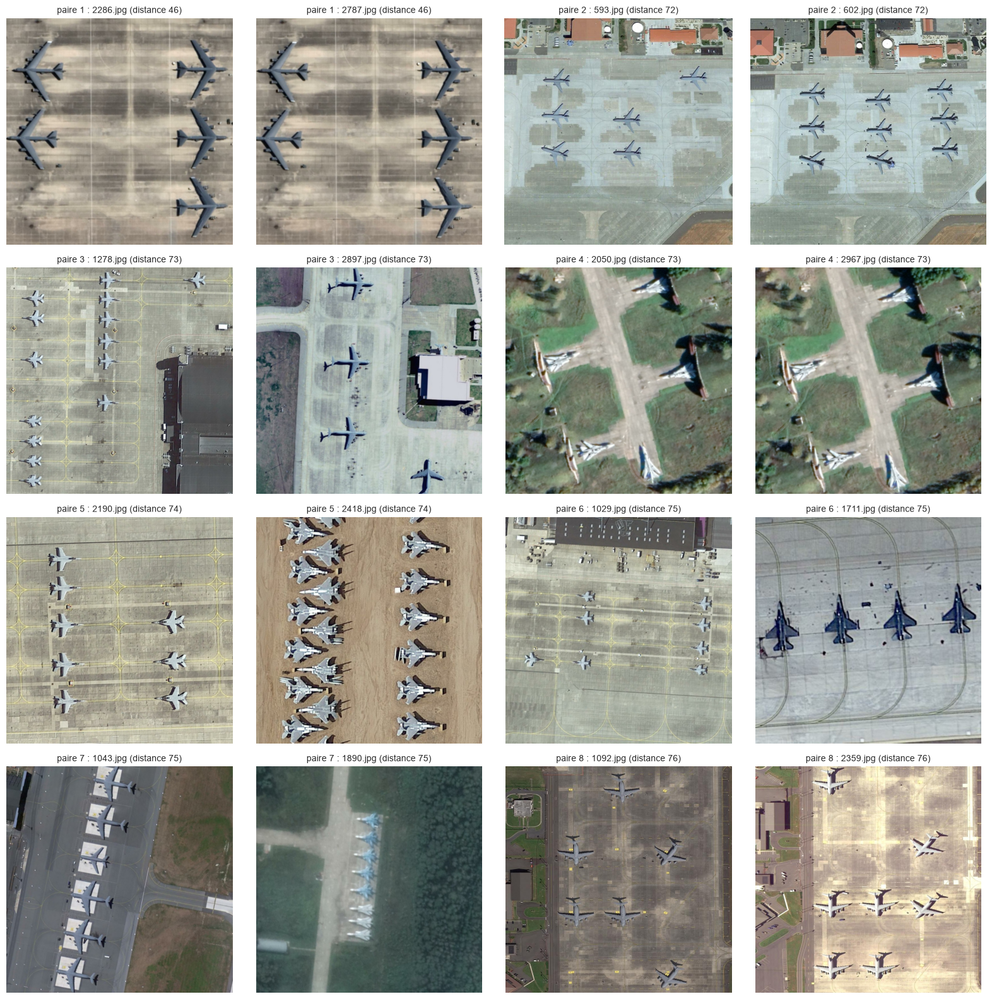

In [12]:
plus_proches = paires.nsmallest(8, "distance")
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for k, paire in enumerate(plus_proches.itertuples()):
    for m, image_id in enumerate((paire.image_a, paire.image_b)):
        ax = axes.flat[2 * k + m]
        ax.imshow(load_image_rgb(RAW_IMAGES_DIR / f"{image_id}.jpg"))
        ax.set_title(f"paire {k + 1} : {image_id}.jpg (distance {paire.distance})", fontsize=10)
        ax.axis("off")
plt.tight_layout()
save(fig, "00_quasi_doublons")
plt.show()

> **Tes observations sur les doublons** *(double-clique ici pour écrire)* :
>
> - les paire 1 et 4 sont identique les autre ce ressemble mais pas identique et la paire 6 n'as aucune ressemblance
> - **Complément** *(rédigé par Claude, à relire et à reformuler avec tes mots)* : la paire 2 (593 / 602) est la **même base à une autre date** : on reconnaît les mêmes bâtiments et les mêmes parkings, mais les avions ont bougé. Pour le découpage, elle compte comme un quasi-doublon : le décor est le même.
> - Aucun doublon exact (MD5).
> - Conséquence : les paires 1, 2 et 4 doivent tomber dans le **même jeu** (train, validation ou test), sinon il y a fuite de données.
> - Limite : l'empreinte dHash ne repère pas deux vues très décalées d'une même base.

### 2.5 Crédibilité : les cas extrêmes

Le cours demande de chercher les **valeurs impossibles**, comme *« un âge négatif, un poids de 800 kg »*. Pour nous : un « avion » de 5 pixels, ou une boîte 10 fois plus large que haute, serait suspect.

On affiche les plus petites boîtes, les plus grandes, et celles à la forme la plus allongée. La fonction `vignette` découpe un **carré centré sur l'avion**, un peu plus grand que la boîte, et l'agrandit à la même taille d'affichage. C'est un premier prototype des vignettes de l'étape 3.

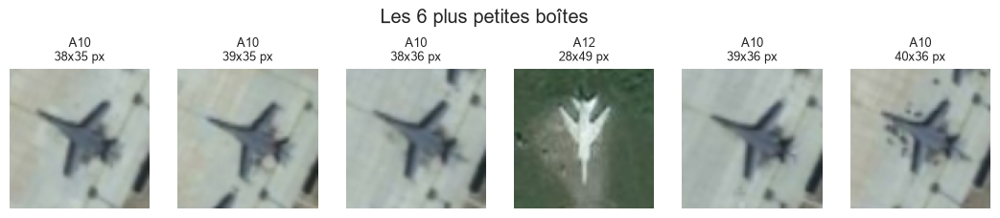

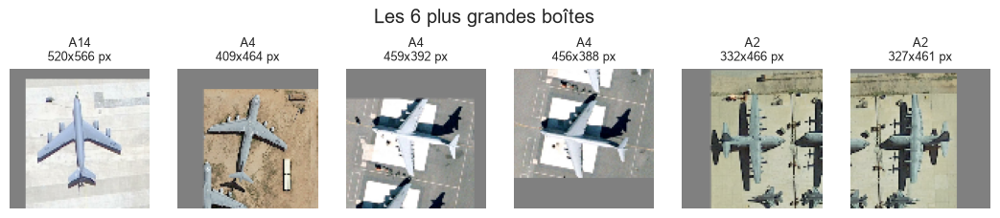

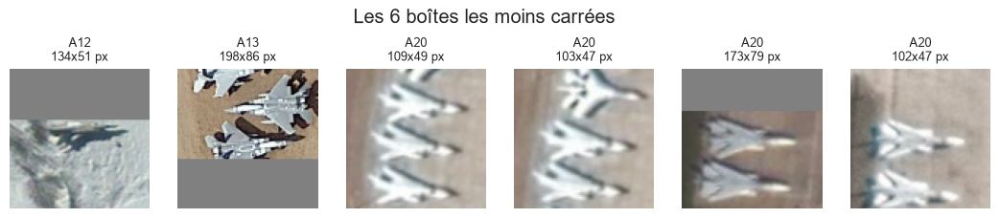

In [13]:
def vignette(avion, facteur=1.5, taille=96):
    # Carré centré sur l'avion, de côté = facteur x plus grand côté de la boîte, redimensionné
    image = load_image_rgb(RAW_IMAGES_DIR / f"{avion.image_id}.jpg")
    cx, cy = (avion.xmin + avion.xmax) / 2, (avion.ymin + avion.ymax) / 2
    demi_cote = facteur * max(avion.box_width, avion.box_height) / 2
    x0, y0 = int(cx - demi_cote), int(cy - demi_cote)
    x1, y1 = int(cx + demi_cote), int(cy + demi_cote)
    # Si le carré sort de l'image, on ajoute une bordure grise autour de l'image
    h, w = image.shape[:2]
    marge = max(0, -x0, -y0, x1 - w, y1 - h)
    image = np.pad(image, ((marge, marge), (marge, marge), (0, 0)), constant_values=128)
    carre = image[y0 + marge : y1 + marge, x0 + marge : x1 + marge]
    return cv2.resize(carre, (taille, taille))


def afficher_vignettes(avions, titre):
    fig, axes = plt.subplots(1, len(avions), figsize=(2.2 * len(avions), 2.8))
    for ax, avion in zip(axes, avions.itertuples()):
        ax.imshow(vignette(avion))
        ax.set_title(f"{avion.class_name}\n{avion.box_width}x{avion.box_height} px", fontsize=9)
        ax.axis("off")
    fig.suptitle(titre)
    plt.show()


afficher_vignettes(df.nsmallest(6, "box_area"), "Les 6 plus petites boîtes")
afficher_vignettes(df.nlargest(6, "box_area"), "Les 6 plus grandes boîtes")
afficher_vignettes(
    df.loc[(df["aspect_ratio"] - 1).abs().nlargest(6).index], "Les 6 boîtes les moins carrées"
)

### 2.6 Avions tronqués et difficiles

Un avion **tronqué** est coupé par le bord de l'image. On vérifie deux choses avec un tableau croisé :
- les avions marqués tronqués touchent-ils bien un bord ? Sinon l'annotation serait incohérente ;
- inversement, y a-t-il des avions qui touchent un bord **sans** être marqués tronqués ?

Avions tronqués   : 331 (4.2 %)
Avions difficiles : 0
touche un bord  False  True 
tronqué                     
False            7293    246
True                0    331


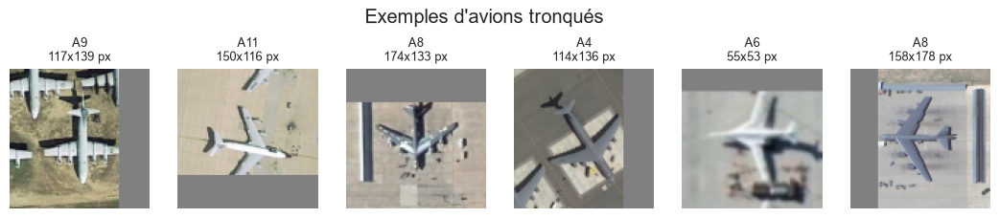

In [14]:
print("Avions tronqués   :", df["truncated"].sum(), f"({100 * df['truncated'].mean():.1f} %)")
print("Avions difficiles :", df["difficult"].sum())

marge = 5  # pixels de tolérance
touche_un_bord = (
    (df["xmin"] <= marge)
    | (df["ymin"] <= marge)
    | (df["xmax"] >= df["image_width"] - marge)
    | (df["ymax"] >= df["image_height"] - marge)
)
print()
print(
    pd.crosstab(df["truncated"], touche_un_bord, rownames=["tronqué"], colnames=["touche un bord"])
)

afficher_vignettes(df[df["truncated"]].sample(6, random_state=0), "Exemples d'avions tronqués")

> **Tes observations sur la qualité des données** :
>
> *(rédigé par Claude, à relire et à reformuler avec tes mots)*
> - Les données sont **propres** :
>   - aucune valeur manquante ;
>   - chaque image a son XML, et inversement ;
>   - aucune boîte vide, à l'envers ou hors de l'image ;
>   - aucune classe inconnue, aucune boîte en double ;
>   - les tailles annoncées dans les XML sont exactes.
>
>   Aucun nettoyage n'est nécessaire.
> - Les plus petites boîtes (environ 38 px) sont encore reconnaissables comme des avions : pas de valeur impossible.
> - 331 avions tronqués (4,2 %). Ils touchent **tous** un bord, donc c'est cohérent. 246 avions non tronqués touchent aussi un bord à 5 px près : ils sont juste au bord, sans être coupés.
> - Aucun avion marqué « difficile ».

## 3. Analyse univariée : une variable à la fois

### 3.1 La cible : combien d'avions par classe ?

`class_name` est une variable **catégorielle** : on compte la fréquence de chaque valeur.

Le cours propose des diagrammes en barres ou des camemberts. Avec 20 catégories, un camembert serait illisible, donc on prend des **barres**.

In [15]:
par_classe = pd.DataFrame(
    {
        "n_avions": df["class_name"].value_counts(),
        "n_images": df.groupby("class_name")["image_id"].nunique(),
    }
).reindex(CLASSES)  # ordre numérique A1, A2, ..., A20
par_classe["pourcentage"] = 100 * par_classe["n_avions"] / par_classe["n_avions"].sum()
par_classe["avions_par_image"] = par_classe["n_avions"] / par_classe["n_images"]
par_classe

,n_avions,n_images,pourcentage,avions_par_image
class_name,,,,
A1,554,117,7.04,4.74
A2,736,67,9.35,10.99
A3,316,84,4.02,3.76
A4,179,44,2.27,4.07
A5,435,135,5.53,3.22
A6,107,29,1.36,3.69
A7,191,71,2.43,2.69
A8,365,79,4.64,4.62
A9,475,56,6.04,8.48


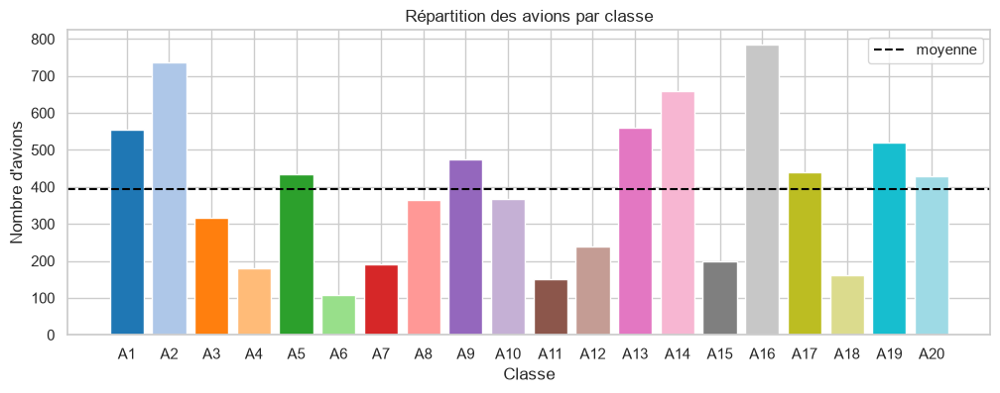

Classe la plus fréquente : A16 (785 avions)
Classe la plus rare      : A6 (107 avions)
Rapport entre les deux   : 7.3


In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(CLASSES, par_classe["n_avions"], color=[PALETTE[c] for c in CLASSES])
ax.axhline(par_classe["n_avions"].mean(), color="black", linestyle="--", label="moyenne")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'avions")
ax.set_title("Répartition des avions par classe")
ax.legend()
save(fig, "01_avions_par_classe")
plt.show()

plus_frequente, plus_rare = par_classe["n_avions"].idxmax(), par_classe["n_avions"].idxmin()
ratio = par_classe["n_avions"].max() / par_classe["n_avions"].min()
print(f"Classe la plus fréquente : {plus_frequente} ({par_classe['n_avions'].max()} avions)")
print(f"Classe la plus rare      : {plus_rare} ({par_classe['n_avions'].min()} avions)")
print(f"Rapport entre les deux   : {ratio:.1f}")

**Pourquoi c'est important :** un modèle qui se trompe systématiquement sur la classe la plus rare peut quand même afficher une très bonne **accuracy** (le pourcentage de bonnes réponses), parce que cette classe pèse peu dans le total.

On utilisera donc la **macro-F1** : le F1-score est calculé classe par classe, puis on fait la moyenne. Chaque classe compte autant, quelle que soit sa taille.

### 3.2 Combien d'avions par image ?

count    1331.00
mean        5.91
std         5.01
min         1.00
25%         3.00
50%         5.00
75%         7.00
max        50.00


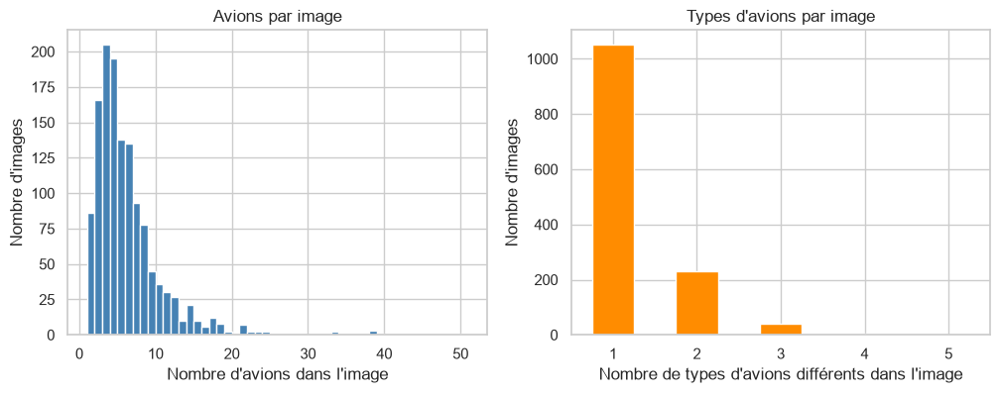

In [17]:
print(images["n_avions"].describe().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(images["n_avions"], bins=range(1, images["n_avions"].max() + 2), color="steelblue")
axes[0].set_xlabel("Nombre d'avions dans l'image")
axes[0].set_ylabel("Nombre d'images")
axes[0].set_title("Avions par image")

images["n_classes"].value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange", rot=0)
axes[1].set_xlabel("Nombre de types d'avions différents dans l'image")
axes[1].set_ylabel("Nombre d'images")
axes[1].set_title("Types d'avions par image")
save(fig, "02_avions_par_image")
plt.show()

### 3.3 Taille des boîtes

C'est une variable **numérique**. Le cours demande :
- les **statistiques descriptives** : moyenne, médiane, quartiles, min, max, écart-type ;
- les **histogrammes**, pour voir la forme de la distribution ;
- les **boîtes à moustaches** (*boxplots*), pour repérer les valeurs aberrantes.

On ajoute `cote_max`, le plus grand côté de la boîte. Il donne une idée de la taille de l'avion, quelle que soit son orientation.

In [18]:
df["cote_max"] = df[["box_width", "box_height"]].max(axis=1)
colonnes_taille = ["box_width", "box_height", "cote_max", "box_area", "aspect_ratio"]
df[colonnes_taille].describe()

,box_width,box_height,cote_max,box_area,aspect_ratio
count,7870.00,7870.00,7870.00,7870.00,7870.00
mean,109.47,109.20,119.39,13307.38,1.04
std,40.28,41.93,41.95,11403.37,0.26
min,28.00,31.00,38.00,1330.00,0.44
25%,82.00,81.00,91.00,6699.00,0.85
50%,100.00,102.00,111.00,10080.00,1.01
75%,132.00,129.00,141.00,16536.00,1.18
max,520.00,566.00,566.00,294320.00,2.63


**Moyenne contre médiane :** la médiane est la valeur du milieu, qui coupe les données en deux moitiés. Si la moyenne est nettement **plus grande** que la médiane, quelques très grandes valeurs tirent la moyenne vers le haut : la distribution est **asymétrique**.

In [19]:
comparaison = pd.DataFrame(
    {"moyenne": df[colonnes_taille].mean(), "médiane": df[colonnes_taille].median()}
)
comparaison["écart (%)"] = (
    100 * (comparaison["moyenne"] - comparaison["médiane"]) / comparaison["médiane"]
)
comparaison

,moyenne,médiane,écart (%)
box_width,109.47,100.00,9.47
box_height,109.20,102.00,7.06
cote_max,119.39,111.00,7.56
box_area,13307.38,10080.00,32.02
aspect_ratio,1.04,1.01,2.92


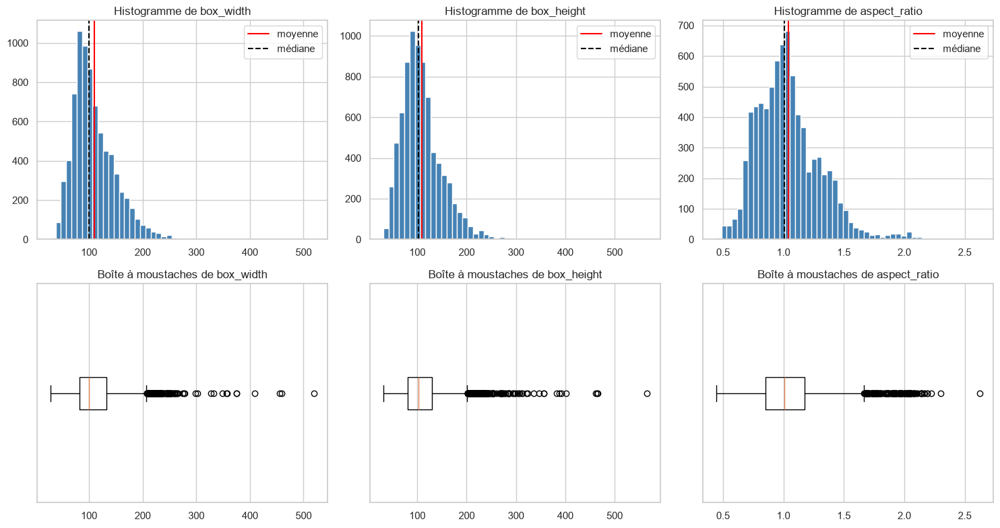

Percentiles du plus grand côté (px) :
0.01     52.00
0.05     66.00
0.25     91.00
0.50    111.00
0.75    141.00
0.95    196.00
0.99    244.31


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for colonne, ax_hist, ax_box in zip(["box_width", "box_height", "aspect_ratio"], axes[0], axes[1]):
    ax_hist.hist(df[colonne], bins=50, color="steelblue")
    ax_hist.axvline(df[colonne].mean(), color="red", label="moyenne")
    ax_hist.axvline(df[colonne].median(), color="black", linestyle="--", label="médiane")
    ax_hist.set_title(f"Histogramme de {colonne}")
    ax_hist.legend()
    ax_box.boxplot(df[colonne], orientation="horizontal")
    ax_box.set_title(f"Boîte à moustaches de {colonne}")
    ax_box.set_yticks([])
plt.tight_layout()
save(fig, "03_tailles_des_boites")
plt.show()

print("Percentiles du plus grand côté (px) :")
print(df["cote_max"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_string())

**Lire une boîte à moustaches :**
- la boîte va du 1er quartile (Q1, 25 % des valeurs en dessous) au 3e quartile (Q3, 75 %) ;
- le trait dans la boîte est la médiane ;
- les moustaches s'étendent jusqu'à 1,5 × (Q3 − Q1) ;
- les points au-delà sont des **valeurs atypiques** (*outliers*). Atypique ne veut pas dire fausse : les grandes boîtes vues en 2.5 sont de vrais gros avions.

### 3.4 Taille des images

In [21]:
print(images[["image_width", "image_height"]].value_counts().head(10).to_string())
print()
print(f"Images carrées : {100 * (images['image_width'] == images['image_height']).mean():.1f} %")

image_width  image_height
800          800             1174
734          734                4
736          736                3
751          751                3
749          749                2
733          733                2
735          735                2
745          745                1
826          789                1
834          738                1
Images carrées : 90.4 %


### 3.5 Où sont les avions dans l'image ?

On trace la position des centres des boîtes en 2D : plus une case est claire, plus il y a d'avions à cet endroit. L'axe y est inversé pour respecter le sens des images, avec y = 0 en haut.

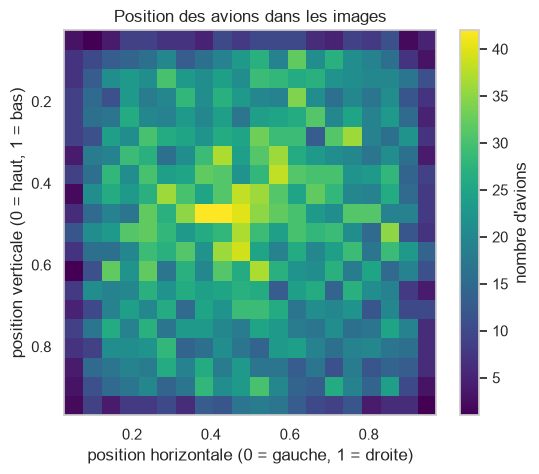

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))
_, _, _, carte = ax.hist2d(df["center_x"], df["center_y"], bins=20, cmap="viridis")
fig.colorbar(carte, ax=ax, label="nombre d'avions")
ax.invert_yaxis()
ax.set_xlabel("position horizontale (0 = gauche, 1 = droite)")
ax.set_ylabel("position verticale (0 = haut, 1 = bas)")
ax.set_title("Position des avions dans les images")
save(fig, "04_positions")
plt.show()

### 3.6 Luminosité et contraste des images

Toutes les images sont-elles prises dans les mêmes conditions d'éclairage ? La réponse nous dira s'il est utile de faire varier la luminosité et le contraste pendant l'entraînement (**data augmentation**).

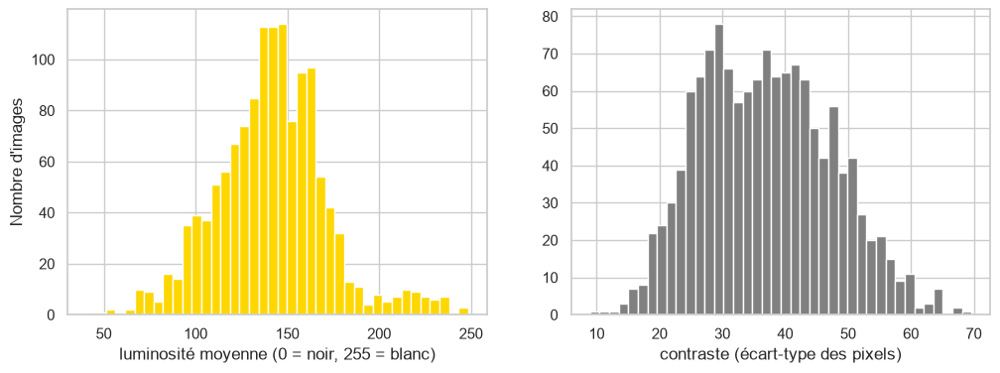

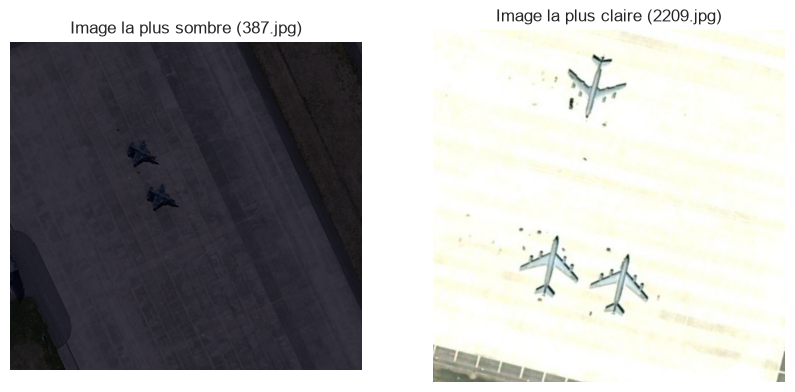

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(images["luminosite"], bins=40, color="gold")
axes[0].set_xlabel("luminosité moyenne (0 = noir, 255 = blanc)")
axes[0].set_ylabel("Nombre d'images")
axes[1].hist(images["contraste"], bins=40, color="gray")
axes[1].set_xlabel("contraste (écart-type des pixels)")
save(fig, "05_luminosite_contraste")
plt.show()

# L'image la plus sombre et la plus claire, pour se rendre compte
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, image_id, titre in zip(
    axes,
    (images["luminosite"].idxmin(), images["luminosite"].idxmax()),
    ("la plus sombre", "la plus claire"),
):
    ax.imshow(load_image_rgb(RAW_IMAGES_DIR / f"{image_id}.jpg"))
    ax.set_title(f"Image {titre} ({image_id}.jpg)")
    ax.axis("off")
plt.show()

> **Tes observations sur l'analyse univariée** :
>
> *(rédigé par Claude, à relire et à reformuler avec tes mots)*
> - **Déséquilibre fort :** A16 compte 785 avions et A6 seulement 107, soit 7,3 fois moins.
> - **Avions par image :** 5 en médiane, jusqu'à 50. 79 % des images (1 052) ne contiennent qu'**un seul type** d'avion.
> - **Taille des boîtes :**
>   - environ 100 × 102 px en médiane ;
>   - plus grand côté : 111 px en médiane, 52 px pour le 1 % le plus petit, 244 px pour le 1 % le plus grand.
>   - La moyenne dépasse la médiane (+32 % pour l'aire) : la distribution est **asymétrique**, tirée vers le haut par quelques très gros avions.
>   - Les boîtes sont presque carrées (rapport médian de 1,01).
> - **Taille des images :** 90 % sont carrées, en 800 × 800. Les autres font entre 730 et 830 px environ.
> - **Position :** il y a des avions partout dans l'image (centre moyen au milieu, 15 % près des bords).
> - **Luminosité :** elle varie beaucoup d'une image à l'autre (moyenne de gris de 41 à 248).

## 4. Analyse bivariée et multivariée : les relations entre variables

### 4.1 Corrélations entre variables numériques

Le **coefficient de corrélation** (de Pearson) mesure à quel point deux variables évoluent ensemble, en ligne droite :
- **+1** : quand l'une augmente, l'autre augmente toujours proportionnellement ;
- **0** : aucun lien linéaire ;
- **−1** : quand l'une augmente, l'autre diminue.

Attention : **corrélation n'est pas causalité**.

On ajoute à chaque avion le nombre d'avions de son image (`n_avions_image`).

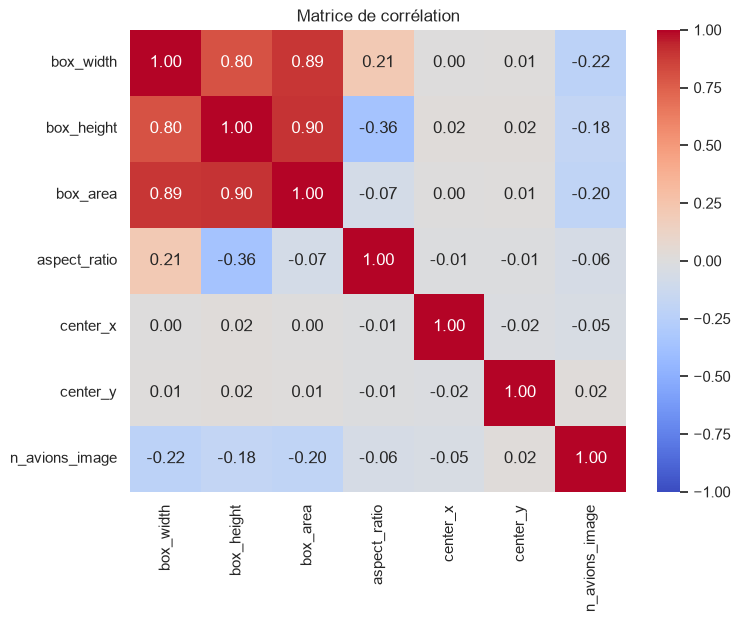

In [24]:
df["n_avions_image"] = df["image_id"].map(images["n_avions"])
colonnes_num = [
    "box_width",
    "box_height",
    "box_area",
    "aspect_ratio",
    "center_x",
    "center_y",
    "n_avions_image",
]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[colonnes_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matrice de corrélation")
save(fig, "06_correlations")
plt.show()

### 4.2 Relation avec la cible : la taille dépend-elle du type d'avion ?

Le cours dit que c'est *« la partie la plus importante »*. On compare une variable numérique (la taille) selon une catégorie (la classe), avec des **boîtes à moustaches groupées**.

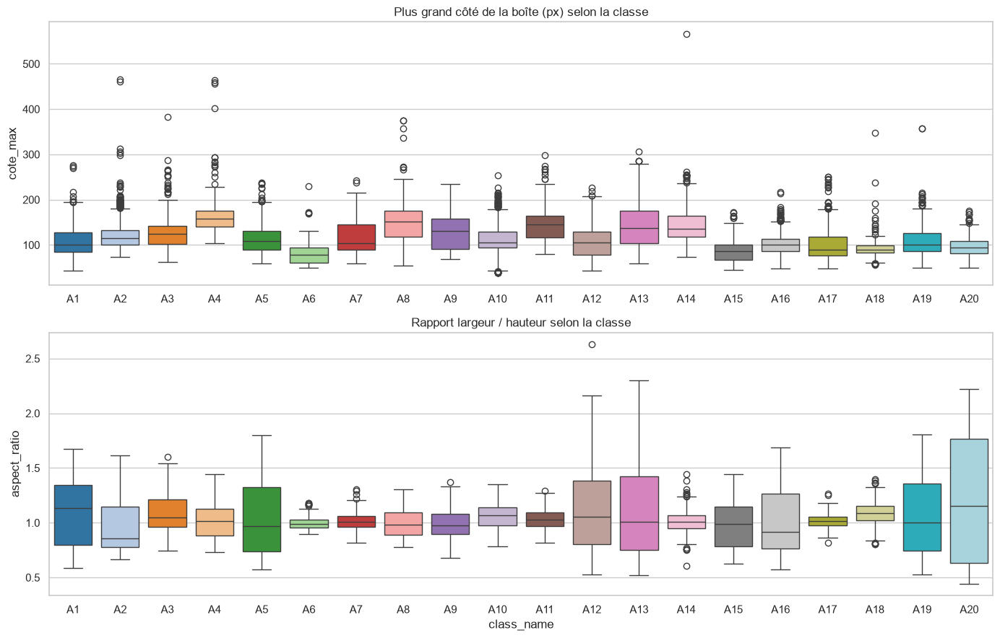

,médiane du plus grand côté (px)
class_name,
A6,78.0
A15,87.0
A17,89.0
A18,90.0
A20,94.0
A19,100.0
A1,100.5
A16,101.0
A7,104.0


In [25]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
sns.boxplot(
    data=df,
    x="class_name",
    y="cote_max",
    order=CLASSES,
    hue="class_name",
    palette=PALETTE,
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Plus grand côté de la boîte (px) selon la classe")
axes[0].set_xlabel("")
sns.boxplot(
    data=df,
    x="class_name",
    y="aspect_ratio",
    order=CLASSES,
    hue="class_name",
    palette=PALETTE,
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Rapport largeur / hauteur selon la classe")
plt.tight_layout()
save(fig, "07_taille_par_classe")
plt.show()

df.groupby("class_name")["cote_max"].median().sort_values().to_frame(
    "médiane du plus grand côté (px)"
)

**À méditer pour l'étape de classification :** toutes les vignettes seront redimensionnées à la même taille avant d'entrer dans le réseau (par exemple 224 × 224). Le réseau verra donc un petit avion et un gros avion **à la même taille**. Si la taille aide à distinguer certaines classes, cette information est perdue. Comment pourrait-on la garder ?

### 4.3 Quels types d'avions apparaissent ensemble ?

On construit un **tableau croisé** (*cross-tab*), une variable catégorielle contre une autre. Chaque case indique le nombre d'images qui contiennent **à la fois** la classe de la ligne et celle de la colonne. Sur la diagonale, on lit le nombre d'images qui contiennent cette classe.

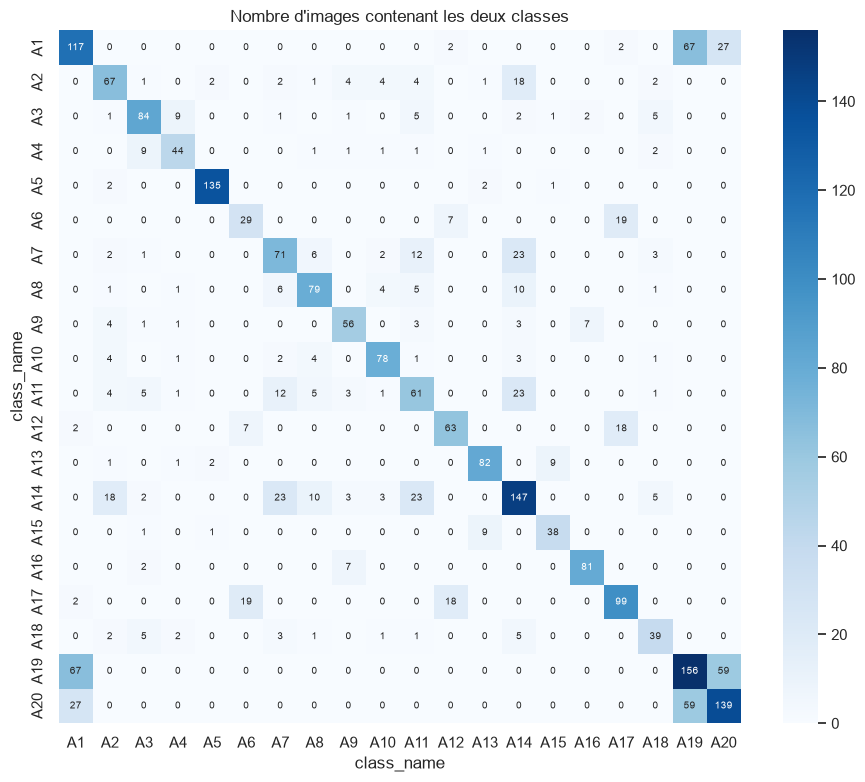

In [26]:
# presence : une ligne par image, une colonne par classe, 1 si la classe est présente dans l'image
presence = (pd.crosstab(df["image_id"], df["class_name"]).reindex(columns=CLASSES) > 0).astype(int)
cooccurrence = presence.T @ presence  # produit matriciel : nombre d'images en commun

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 7}, ax=ax)
ax.set_title("Nombre d'images contenant les deux classes")
save(fig, "08_cooccurrence")
plt.show()

### 4.4 Les avions d'une même classe sont-ils regroupés ?

Pour chaque image et chaque classe présente, on compte combien d'avions de cette classe il y a. Une classe avec beaucoup d'avions **dans peu d'images** est concentrée sur quelques bases aériennes.

C'est important pour le découpage train / validation / test, qui se fera **par image**. Si une image contient 40 avions A2, les 40 tombent ensemble dans le même jeu.

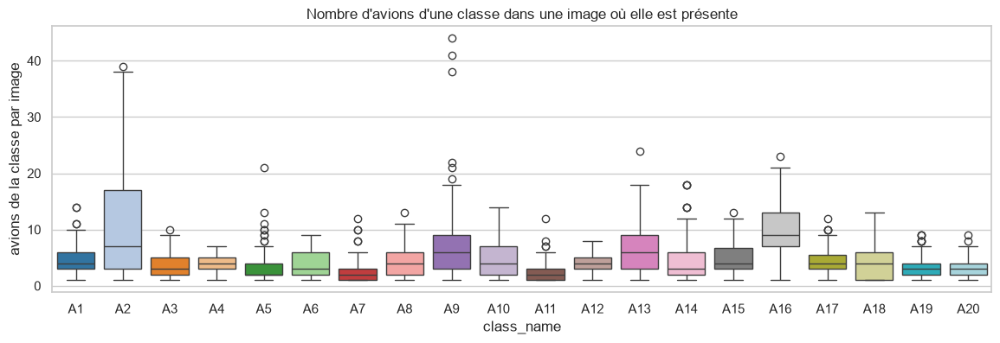

,n_avions,n_images,avions_par_image
class_name,,,
A2,736,67,10.99
A16,785,81,9.69
A9,475,56,8.48
A13,561,82,6.84
A15,200,38,5.26


In [27]:
par_image_et_classe = df.groupby(["image_id", "class_name"]).size().rename("n").reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(
    data=par_image_et_classe,
    x="class_name",
    y="n",
    order=CLASSES,
    hue="class_name",
    palette=PALETTE,
    legend=False,
    ax=ax,
)
ax.set_ylabel("avions de la classe par image")
ax.set_title("Nombre d'avions d'une classe dans une image où elle est présente")
save(fig, "09_concentration_par_classe")
plt.show()

par_classe.sort_values("avions_par_image", ascending=False)[
    ["n_avions", "n_images", "avions_par_image"]
].head(5)

> **Tes observations sur les relations entre variables** :
>
> *(rédigé par Claude, à relire et à reformuler avec tes mots)*
> - **Largeur et hauteur des boîtes :** fortement corrélées (0,80). C'est logique, les deux suivent la taille de l'avion.
> - **Aire et nombre d'avions dans l'image :** faiblement anticorrélées (−0,20). Les images très chargées contiennent plutôt de petits avions, par exemple des chasseurs alignés.
> - **Taille et type d'avion :** la taille dépend beaucoup du type. Le plus grand côté médian va de **78 px (A6) à 158 px (A4)**.
>   - La taille est donc un bon indice.
>   - Mais elle est perdue quand on redimensionne toutes les vignettes à la même taille.
> - **Concentration par image :**
>   - la plupart des images ne contiennent qu'un seul type ;
>   - certaines classes sont très regroupées : A2 a environ 11 avions par image, A16 9,7, A9 8,5.
>
>   Quelques images portent beaucoup d'avions d'une même classe : il faut un découpage **stratifié**.

## 5. Voir les données

Les chiffres ne suffisent pas : il faut **regarder** les images.

### 5.1 Quelques images avec leurs annotations

On tire 4 images au hasard et on dessine les boîtes avec `draw_boxes` (définie au début du notebook). Chaque classe a sa couleur.

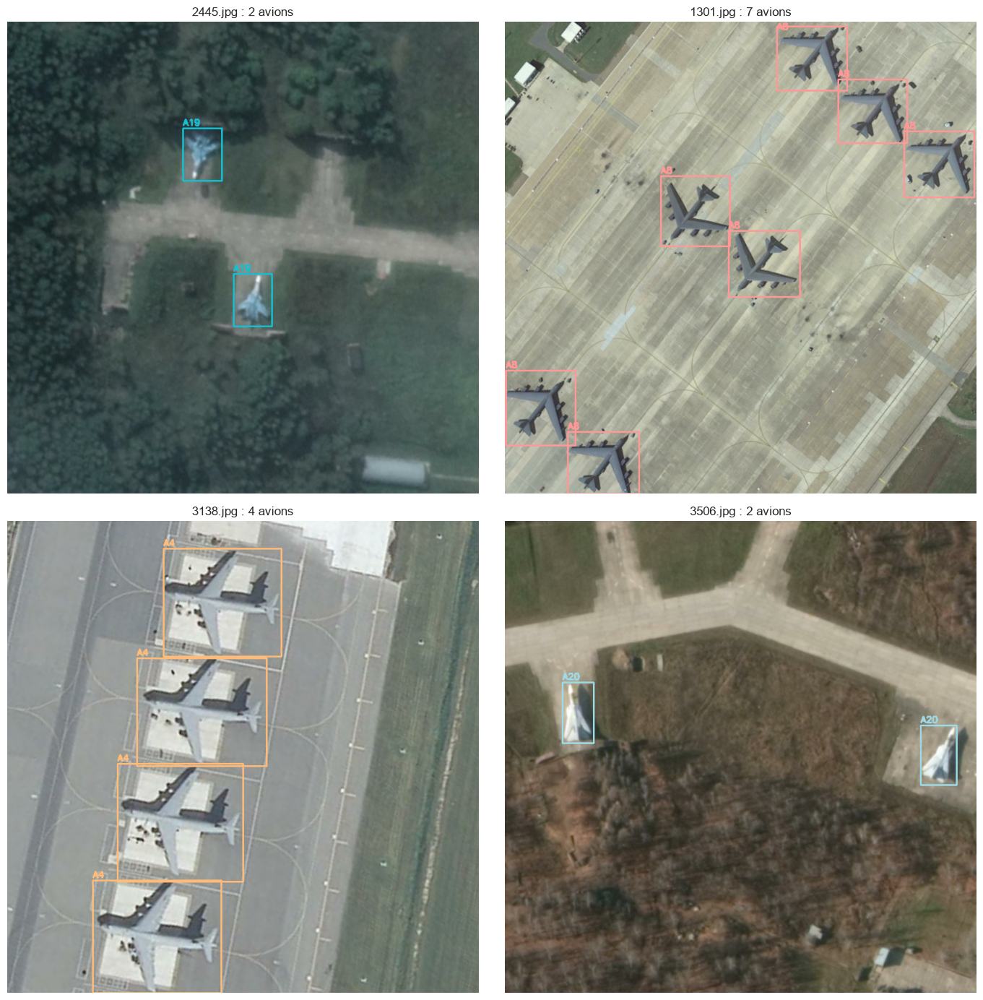

In [28]:
exemples = rng.choice(images.index, size=4, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, image_id in zip(axes.flat, exemples):
    avions = df[df["image_id"] == image_id]
    image = load_image_rgb(RAW_IMAGES_DIR / f"{image_id}.jpg")
    boites = avions[["xmin", "ymin", "xmax", "ymax"]].values.tolist()
    ax.imshow(draw_boxes(image, boites, avions["class_name"].tolist()))
    ax.set_title(f"{image_id}.jpg : {len(avions)} avions")
    ax.axis("off")
plt.tight_layout()
save(fig, "10_exemples_annotes")
plt.show()

### 5.2 Galerie : à quoi ressemble chaque type d'avion ?

Une ligne par classe, avec 8 avions tirés au hasard. Regarde bien :
- les classes sont-elles faciles à distinguer à l'œil ? Lesquelles se ressemblent ?
- les avions ont-ils une **orientation** privilégiée (nez vers le haut, vers la droite…) ?
- les couleurs, les ombres et le fond (tarmac, herbe) varient-ils ?

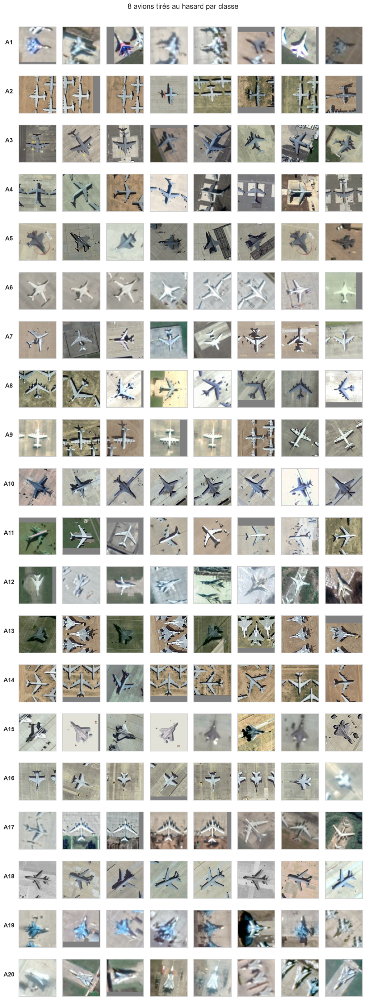

In [29]:
n_par_classe = 8
fig, axes = plt.subplots(
    len(CLASSES), n_par_classe, figsize=(n_par_classe * 1.3, len(CLASSES) * 1.4)
)
for ligne, classe in zip(axes, CLASSES):
    avions_classe = df[df["class_name"] == classe]
    tirage = avions_classe.iloc[rng.choice(len(avions_classe), size=n_par_classe, replace=False)]
    for ax, avion in zip(ligne, tirage.itertuples()):
        ax.imshow(vignette(avion))
        ax.set_xticks([])
        ax.set_yticks([])
    ligne[0].set_ylabel(classe, rotation=0, labelpad=20, fontsize=12, fontweight="bold")
fig.suptitle("8 avions tirés au hasard par classe", y=1.0)
plt.tight_layout()
save(fig, "11_galerie_par_classe")
plt.show()

> **Tes observations sur les images** :
>
> *(rédigé par Claude, à relire et à reformuler avec tes mots)*
> - Les grandes familles se distinguent bien à l'œil : gros transporteurs ou ravitailleurs, bombardiers, chasseurs.
> - Certains chasseurs se ressemblent beaucoup, par exemple A1, A13, A19 et A20. C'est probablement là que le classifieur se trompera le plus.
> - **Aucune orientation privilégiée :** les avions pointent dans toutes les directions.
> - Le décor varie beaucoup : béton, sable, herbe, ombres. Certaines images sont floues.

## 6. Conclusions

Réponds à ces questions avec tes mots, à partir de ce que tu as vu. Ce sont typiquement les questions qu'un prof pose à l'oral.

1. Quelle classe est la plus rare, et la plus fréquente ? Quel est le rapport entre les deux ? Pourquoi l'**accuracy** seule serait-elle trompeuse ?
2. Quelle est la taille typique d'un avion, en pixels ? Les plus petits sont-ils encore reconnaissables ? Faut-il réduire la taille des images avant de les donner au détecteur ?
3. Les avions ont-ils une orientation privilégiée ? Quelle **augmentation de données** cela suggère-t-il ? Et laquelle serait une mauvaise idée pour des images vues du ciel ?
4. La taille d'un avion dépend-elle de sa classe ? Que perd-on en redimensionnant toutes les vignettes à la même taille ?
5. As-tu trouvé des doublons ou quasi-doublons ? Pourquoi est-ce dangereux pour le découpage train / validation / test ?
6. Pourquoi doit-on découper **par image** et non **par avion** ?

> **Tes réponses** *(rédigé par Claude, à relire et à reformuler avec tes mots)* :
>
> 1. **Classes extrêmes :**
>    - la plus rare est **A6** (107 avions) ;
>    - la plus fréquente est **A16** (785) ;
>    - il y a un rapport de **7,3** entre les deux.
>
>    L'accuracy compte chaque avion une fois. Un modèle qui raterait **tous** les A6 ne perdrait donc que 1,4 % d'accuracy, alors qu'il est inutile sur cette classe. La **macro-F1** donne le même poids à chaque classe, donc elle révèle ce problème.
> 2. **Taille des avions :**
>    - environ **100 px** de côté (plus grand côté médian : 111 px) ;
>    - les plus petits font environ 38 px et restent reconnaissables.
>
>    YOLO réduit les images à 640 px par défaut. Nos avions rétréciraient alors de 20 % : 38 px deviendraient 30 px, ce qui se rapproche de la limite. On garde donc la **résolution native de 800 px** pour le détecteur, qui tient dans la mémoire de la carte graphique.
> 3. **Orientation :** il n'y en a **aucune** de privilégiée. Les **rotations** et les **retournements** sont donc des augmentations naturelles :
>    - pour le détecteur, des rotations de 90° seulement, qui gardent les boîtes exactes ;
>    - pour les vignettes, n'importe quel angle.
>
>    Ce seraient de mauvaises idées :
>    - les déformations de **perspective** ou de cisaillement, car une image satellite est prise du dessus, sans perspective ;
>    - les changements de couleur extrêmes ;
>    - les recadrages qui coupent l'avion.
>
>    Les variations de **luminosité et de contraste** sont utiles, puisque la luminosité varie de 41 à 248.
> 4. **Taille et classe :** oui, la taille dépend de la classe (78 px en médiane pour A6, 158 px pour A4). En redimensionnant toutes les vignettes en 224 × 224, le réseau ne voit plus que la **forme** : il perd la taille réelle.
>
>    Piste d'amélioration : donner la taille de la boîte au classifieur, en plus de l'image. Attention, la résolution au sol (combien de mètres par pixel) peut varier d'une image à l'autre.
> 5. **Doublons :** aucun doublon exact, mais **3 paires de quasi-doublons** confirmées à l'œil :
>    - 2286 / 2787 : identiques ;
>    - 2050 / 2967 : même scène ;
>    - 593 / 602 : même base, autre date.
>
>    Si l'une est dans le train et l'autre dans le test, le modèle est évalué sur une image qu'il a pratiquement déjà vue. Son score est alors trop optimiste : c'est une **fuite de données**. Au découpage, on les met donc dans le **même groupe**.
> 6. **Découper par image, pas par avion :** les avions d'une même image partagent :
>    - le même décor ;
>    - la même lumière ;
>    - la même date ;
>    - et souvent le même type.
>
>    Découper par avion mettrait des « frères » dans le train et dans le test. Ce serait encore une fuite de données, et le score serait faussement bon.

### Ce que l'EDA change pour la suite du projet *(rédigé par Claude, à relire et à reformuler avec tes mots)*

| Constat | Conséquence pour le projet |
|---|---|
| Classes déséquilibrées (A6 a 7,3 fois moins d'avions que A16) | **macro-F1** comme métrique, pondération des classes rares, découpage **stratifié** |
| Avions d'environ 100 px, les plus petits vers 38 px | détecteur en **800 px**, sans réduction à 640 |
| Aucune orientation privilégiée | augmentation par **rotations et retournements** |
| Luminosité très variable (41 à 248) | augmentation de **luminosité et de contraste** |
| La taille dépend du type d'avion | information perdue par le redimensionnement des vignettes : piste d'amélioration |
| 3 paires de quasi-doublons | regroupées dans le **même jeu** au découpage |
| Avions d'une même image très liés (décor, type) | découpage **par image** |
| 79 % des images ne contiennent qu'un seul type | piste d'amélioration : le « vote par image » |
| Données propres (aucun manque, aucune boîte incohérente) | aucun nettoyage nécessaire |
| 331 avions tronqués (4,2 %), tous au bord | gardés ; vignettes complétées par une bordure grise |